# Op3nSrc — Repo classification (model training & evaluation)

**Task:** given a developer's text profile, predict **which repo they contribute to**. The app shows the
5 most likely repos, so this is the model behind "projects that fit you".

| | |
|---|---|
| One row | one developer |
| Features (`text`) | their merged-PR titles + bodies (owner names and `owner/repo` strings removed so the label is not given away) |
| Label (`repo`) | the repo they merged most PRs into |
| Classes | repos with ≥ 5 developers |
| Split | standard **stratified random 80/20** train/test split |
| Model choice | 4-fold cross-validation on the **training** set |
| Metrics | accuracy, **top-5 accuracy** (true repo among the 5 recommended), macro / weighted F1 |

Code: `recommender/classification.py` (dataset, split, metrics) and `recommender/models.py` (models).

In [1]:
import sys
from pathlib import Path

# make the project root importable whether the notebook runs from the root or notebooks/
ROOT = Path.cwd() if (Path.cwd() / "recommender").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold, cross_validate

from recommender.data import load_all
from recommender.classification import build_dataset, split, scores
from recommender.models import make_classifiers

tables = load_all()

## 1. Dataset

In [2]:
df = build_dataset(tables)
print(f"{len(df):,} developers (rows), {df.repo.nunique()} repos (classes)")
df.head()

1,724 developers (rows), 117 repos (classes)


,developer,text,repo,n_prs
0,0-wiz-0,fix strftime-related functions on netbsd.. clo...,jqlang/jq,2
1,00200200,fix: replace deprecated jsonschema refresolver...,altair-viz/altair,1
2,0guban0v,fix: synchronize pr label matchers. closes #29...,pola-rs/polars,6
3,0jaspahwa,caddyfile: clarify argerr documentation. close...,caddyserver/caddy,1
4,0xC61,fix: fix incorrect condition in and add test. ...,pola-rs/polars,1


In [3]:
per_repo = df.repo.value_counts()
print("developers per repo: min", per_repo.min(), "| median", int(per_repo.median()), "| max", per_repo.max())
print("words per profile: median", int(df.text.str.split().str.len().median()))

developers per repo: min 5 | median 13 | max 39
words per profile: median 92


## 2. Train / test split

In [4]:
train, test = split(df)
print(f"train: {len(train):,} rows | test: {len(test):,} rows | every repo in both: "
      f"{set(train.repo) == set(test.repo)}")

train: 1,379 rows | test: 345 rows | every repo in both: True


## 3. Choose the model — cross-validation on the training set

The test set is not touched here. Each model is trained and scored 4 times on different parts of the
training data.

In [5]:
cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=42)
models = make_classifiers()
cv_results = {}
for name, model in models.items():
    r = cross_validate(model, train.text, train.repo, cv=cv, scoring=["accuracy", "f1_macro"])
    cv_results[name] = {"CV accuracy": r["test_accuracy"].mean(), "CV macro F1": r["test_f1_macro"].mean()}
cv_results = pd.DataFrame(cv_results).T
cv_results.round(3)

,CV accuracy,CV macro F1
Most frequent repo (baseline),0.022,0.000
TF-IDF + Naive Bayes,0.510,0.376
TF-IDF + Logistic Regression,0.496,0.341
Sentence-BERT + Logistic Regression,0.425,0.293


In [6]:
best = cv_results["CV accuracy"].idxmax()
print("Best model (cross-validation):", best)

Best model (cross-validation): TF-IDF + Naive Bayes


## 4. Test set — final numbers

In [7]:
test_results = {}
for name, model in models.items():
    model.fit(train.text, train.repo)
    test_results[name] = scores(model, test.text, test.repo)
test_results = pd.DataFrame(test_results).T
test_results.round(3)

,accuracy,top-5 accuracy,macro F1,weighted F1
Most frequent repo (baseline),0.023,0.061,0.000,0.001
TF-IDF + Naive Bayes,0.507,0.730,0.360,0.450
TF-IDF + Logistic Regression,0.533,0.699,0.347,0.476
Sentence-BERT + Logistic Regression,0.441,0.684,0.313,0.392


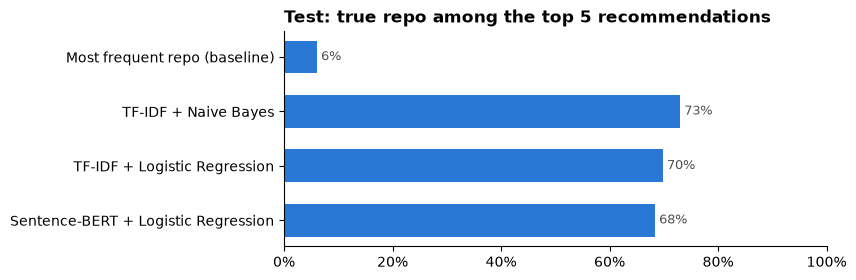

In [8]:
fig, ax = plt.subplots(figsize=(7, 2.8))
s = test_results["top-5 accuracy"].iloc[::-1]
ax.barh(s.index, s.values, color="#2a78d6", height=0.6)
for y, v in enumerate(s.values):
    ax.text(v, y, f" {v:.0%}", va="center", fontsize=9, color="#52514e")
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.set_title("Test: true repo among the top 5 recommendations", loc="left", fontweight="bold");

In [9]:
out = ROOT / "results"
out.mkdir(exist_ok=True)
test_results.round(4).to_csv(out / "test_results.csv", index_label="model")
print("saved", (out / "test_results.csv").relative_to(ROOT))

saved results/test_results.csv


## 5. Which repos are easy or hard to recognise? (best model)

In [10]:
model = models[best]
pred = model.predict(test.text)
per_repo_f1 = pd.Series(f1_score(test.repo, pred, labels=model.classes_, average=None, zero_division=0),
                        index=model.classes_)
pd.DataFrame({"easiest (highest F1)": per_repo_f1.nlargest(8).round(2).reset_index().agg(lambda r: f"{r.iloc[0]} ({r.iloc[1]})", axis=1).values,
              "hardest (lowest F1)": per_repo_f1.nsmallest(8).round(2).reset_index().agg(lambda r: f"{r.iloc[0]} ({r.iloc[1]})", axis=1).values})

,easiest (highest F1),hardest (lowest F1)
0,argoproj/argo-workflows (1.0),Automattic/mongoose (0.0)
1,encode/django-rest-framework (1.0),altair-viz/altair (0.0)
2,geopandas/geopandas (1.0),angular/angular (0.0)
3,hashicorp/terraform (1.0),apache/druid (0.0)
4,jax-ml/jax (1.0),bokeh/bokeh (0.0)
5,jestjs/jest (1.0),caddyserver/caddy (0.0)
6,syncthing/syncthing (1.0),clap-rs/clap (0.0)
7,mlflow/mlflow (0.89),cli/cli (0.0)


In [11]:
mistakes = pd.DataFrame({"true repo": test.repo.values, "predicted": pred})
mistakes = mistakes[mistakes["true repo"] != mistakes["predicted"]]
mistakes.value_counts().head(10).rename("count").to_frame()

,,count
true repo,predicted,
spring-projects/spring-boot,argoproj/argo-cd,2
numpy/numpy,huggingface/transformers,2
facebook/react,sveltejs/svelte,2
ocaml/ocaml,celery/celery,1
electron/electron,matplotlib/matplotlib,1
litestar-org/litestar,vercel/next.js,1
flutter/flutter,kubernetes/kubernetes,1
square/okhttp,go-gitea/gitea,1
TanStack/query,traefik/traefik,1


## 6. Takeaways

- **The task is learnable:** with 117 repos, guessing the most common repo is right 2% of the time;
  TF-IDF + Naive Bayes gets the exact repo **51%** of the time and has the true repo in its
  **top 5 for 73%** of developers on the test set.
- **TF-IDF + Naive Bayes** wins cross-validation and is used in the app. Logistic Regression is very close
  (slightly higher exact accuracy, lower top-5); Sentence-BERT embeddings are behind — exact project and
  library names matter more here than general meaning.
- Macro F1 (0.36) is lower than accuracy: small repos with few developers are harder; some repos are
  never predicted correctly.
- Mistakes are mostly between similar projects (e.g. react ↔ svelte, numpy ↔ transformers).
- Limitation: the model is trained on PR text; a new user's profile also contains their own repos and
  starred projects, so app recommendations are less reliable than these test numbers.